# ForecastIQ — Notebook 3B: Two-stage Hurdle LightGBM

**Research question:** Does separating the **probability of a positive sale** from the **quantity sold conditional on a positive sale** improve 28-day intermittent retail demand forecasts?

This notebook uses the **same 400 product-store sample, 3 expanding validation folds, final 28-day test, and direct multi-horizon features** as Notebook 3A. It evaluates Hurdle LightGBM against the calendar LightGBM regression baseline and SES/SBA/TSB. No test outcome is used for model selection.

**Forecast identity:** `E[y | X] = P(y > 0 | X) × E[y | y > 0, X]`.

**Limitations:** This is a balanced, small-sample pilot. Multi-origin outer testing, uncertainty intervals, larger populations and richer features are deferred.

In [16]:
# Shared scientifically validated ForecastIQ framework
import sys
from pathlib import Path
_project = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(_project) not in sys.path:
    sys.path.insert(0, str(_project))
from src.experiments.config import ExperimentConfig, save_manifest
EXPERIMENT_CONFIG = ExperimentConfig()
EXPERIMENT_NAME = '03B_hurdle_lightgbm'
MANIFEST = save_manifest(_project / 'results' / 'manifests' / (EXPERIMENT_NAME + '.json'), EXPERIMENT_NAME, EXPERIMENT_CONFIG, sources=[_project / 'data' / 'raw' / 'sales_train_validation.csv'])
print('Experiment manifest:', MANIFEST['experiment_id'])


Experiment manifest: 03B_hurdle_lightgbm-20261101T103144Z


## 1 — Setup and data (compatible with Notebook 3A)

Install once if needed: `%pip install lightgbm pandas numpy scikit-learn matplotlib`. Run Notebook 1 before this notebook.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error
try:
    import lightgbm as lgb
except ImportError as e:
    raise ImportError('Install LightGBM with: %pip install lightgbm') from e

PROJECT = Path.cwd()
if not (PROJECT / 'data').exists() and (PROJECT.parent / 'data').exists():
    PROJECT = PROJECT.parent
RAW = PROJECT / 'data' / 'raw'
OUT = PROJECT / 'data' / 'processed'
OUT.mkdir(parents=True, exist_ok=True)
SALES_FILE = OUT / 'm5_sample_400.csv'
META_FILE = OUT / 'm5_sample_400_metadata.csv'
assert SALES_FILE.exists() and META_FILE.exists(), 'Run Notebook 1 first to create the 400-series sample.'
SEED = 42
HORIZON = 28
N_FOLDS = 3
ORIGIN_STEP = 28   # historic forecast origins, never overlapping labels for one origin
MIN_HISTORY = 112
MAX_SERIES = None  # e.g. 80 for a quick smoke test; None => all 400
print('Project:', PROJECT)
print('LightGBM version:', lgb.__version__)

In [18]:
sales = pd.read_csv(SALES_FILE)
meta = pd.read_csv(META_FILE)
day_cols = sorted([c for c in sales if c.startswith('d_') and c[2:].isdigit()], key=lambda c:int(c[2:]))
assert day_cols and len(day_cols) > MIN_HISTORY + (N_FOLDS+2)*HORIZON
assert sales.series_id.is_unique and meta.series_id.is_unique
s = sales.merge(meta[['series_id','demand_type']], on='series_id', validate='one_to_one')
if MAX_SERIES is not None:
    s = s.groupby('demand_type', group_keys=False).head(max(1, MAX_SERIES // 4)).reset_index(drop=True)
values = s[day_cols].apply(pd.to_numeric, errors='coerce')
assert values.notna().all().all(), 'Missing or invalid sales detected'
assert (values >= 0).all().all(), 'Negative sales detected'
Y = values.to_numpy(dtype=np.float32)
S, T = Y.shape
assert S >= 4
ids = s['series_id'].to_numpy()
label_types = s['demand_type'].to_numpy()
test_origin = T-HORIZON
print(f'{S} series × {T} days; train through d_{test_origin}; test d_{test_origin+1}…d_{T}')
display(s.demand_type.value_counts().rename_axis('demand_type').to_frame('series'))

400 series × 1913 days; train through d_1885; test d_1886…d_1913


,series
demand_type,
Smooth,100
Erratic,100
Intermittent,100
Lumpy,100


In [19]:
calendar_path = RAW / 'calendar.csv'
if calendar_path.exists():
    calendar = pd.read_csv(calendar_path, usecols=['d','date']).drop_duplicates('d')
    day_dates = pd.to_datetime(calendar.set_index('d').reindex(day_cols)['date'])
    assert day_dates.notna().all(), 'calendar.csv is missing required d_ dates'
    DATE_SOURCE = 'calendar.csv'
else:
    # M5 day d_1 is 2011-01-29. Verify against official calendar if it becomes available.
    day_dates = pd.Series(pd.date_range('2011-01-29', periods=T, freq='D'), index=day_cols)
    DATE_SOURCE = 'M5 d_1 fallback (2011-01-29)'
dates = pd.DatetimeIndex(day_dates.to_numpy())
print('Date source:', DATE_SOURCE, '| first:', dates[0].date(), '| last:', dates[-1].date())

Date source: calendar.csv | first: 2011-01-29 | last: 2016-04-24


In [20]:
# Reload so an already-running Jupyter kernel cannot retain an older feature schema.
from importlib import reload
import src.features.feature_engineering as feature_engineering
feature_engineering = reload(feature_engineering)

def snapshot_features(history):
    output = feature_engineering.historical_snapshot(history)
    required = {'last_28_vs_prev_28'}
    missing = required.difference(output)
    if missing:
        raise RuntimeError(f'Shared feature schema is missing: {sorted(missing)}')
    return output

# Series code is a categorical indicator. Demand type is not used as a feature.
series_index = np.arange(S, dtype=np.int32)

def make_origin_rows(origin, with_target=True):
    # Create S x horizon rows using history strictly before origin.
    assert MIN_HISTORY <= origin <= T-HORIZON
    snap = snapshot_features(Y[:, :origin])
    rows = {key: np.repeat(value, HORIZON) for key, value in snap.items()}
    rows['series_code'] = np.repeat(series_index, HORIZON)
    rows['horizon'] = np.tile(np.arange(1, HORIZON+1, dtype=np.int16), S)
    future_dates = dates[origin:origin+HORIZON]
    rows['day_of_week'] = np.tile(future_dates.dayofweek.to_numpy(dtype=np.int8), S)
    rows['month'] = np.tile(future_dates.month.to_numpy(dtype=np.int8), S)
    frame = pd.DataFrame(rows)
    if with_target:
        return frame, Y[:,origin:origin+HORIZON].reshape(-1)
    return frame

example_x, example_y = make_origin_rows(test_origin)
display(example_x.head(7))
print('28 future prediction rows per series:', len(example_x), 'total')


,lag_1,lag_7,lag_14,lag_28,lag_56,mean_7,std_7,zero_ratio_7,mean_28,std_28,zero_ratio_28,mean_56,std_56,zero_ratio_56,last_28_vs_prev_28,series_code,horizon,day_of_week,month
0,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,1,0,3
1,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,2,1,3
2,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,3,2,3
3,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,4,3,3
4,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,5,4,4
5,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,6,5,4
6,3.0,0.0,14.0,0.0,0.0,4.428571,9.678506,0.714286,4.357143,6.735908,0.571429,2.178571,5.237595,0.785714,4.357143,0,7,6,4


28 future prediction rows per series: 11200 total


In [21]:
validation_origins = [test_origin-HORIZON*i for i in range(N_FOLDS,0,-1)]
assert validation_origins[-1]+HORIZON == test_origin

def training_origins_before(origin):
    return list(range(MIN_HISTORY, origin-HORIZON+1, ORIGIN_STEP))

for origin in validation_origins + [test_origin]:
    origins = training_origins_before(origin)
    assert origins and max(origins)+HORIZON <= origin
    print('forecast origin:', origin, '| historical training origins:', len(origins),
          '| final train label ends:', max(origins)+HORIZON,
          '| forecast days:', f'{origin+1}..{origin+HORIZON}')

# Demonstrate that changing validation future sales does not modify validation features.
probe = test_origin
first_snapshot = make_origin_rows(probe, with_target=False)
original = Y[0, probe]
Y[0, probe] = original + 1234
second_snapshot = make_origin_rows(probe, with_target=False)
Y[0, probe] = original
pd.testing.assert_frame_equal(first_snapshot, second_snapshot)
print('Leakage smoke test PASSED: features do not depend on future actual sales.')

forecast origin: 1801 | historical training origins: 60 | final train label ends: 1792 | forecast days: 1802..1829
forecast origin: 1829 | historical training origins: 61 | final train label ends: 1820 | forecast days: 1830..1857
forecast origin: 1857 | historical training origins: 62 | final train label ends: 1848 | forecast days: 1858..1885
forecast origin: 1885 | historical training origins: 63 | final train label ends: 1876 | forecast days: 1886..1913
Leakage smoke test PASSED: features do not depend on future actual sales.


## 2 — Training features and two-part model

For each historical origin, build 28 prediction rows per product-store. All lag/rolling features are calculated **before** the origin. The future horizon and calendar values are known at forecast time.

- **Classifier target:** `1` when a sale occurs (`y > 0`), otherwise `0`.
- **Positive-quantity regressor:** fit **only on training examples with `y > 0`**; target is the positive number of units.
- **Forecast:** multiply class probability by nonnegative expected conditional quantity.

Both stages use the same LightGBM calendar features as model B in Notebook 3A. We fit a plain regression LightGBM B in parallel to isolate the effect of the hurdle structure.

In [22]:
from src.forecasting.lightgbm_hurdle import fit_predict_hurdle_and_direct_frames
BASE_FEATURES = ['series_code','horizon','lag_1','lag_7','lag_14','lag_28','lag_56',
                 'mean_7','std_7','zero_ratio_7','mean_28','std_28','zero_ratio_28',
                 'mean_56','std_56','zero_ratio_56','last_28_vs_prev_28']
CAL_FEATURES=['day_of_week','month'];FEATURES=BASE_FEATURES+CAL_FEATURES

def data_before(origin):
    pairs=[make_origin_rows(o) for o in training_origins_before(origin)]
    X=pd.concat([x[FEATURES] for x,_ in pairs],ignore_index=True)
    X['series_code']=X['series_code'].astype('category')
    return X,np.concatenate([y for _,y in pairs])

def features_at(origin,train_X):
    X=make_origin_rows(origin,with_target=False)[FEATURES].copy()
    X['series_code']=pd.Categorical(X['series_code'],categories=train_X['series_code'].cat.categories)
    return X

MODEL_ARGS=dict(n_estimators=250,learning_rate=.05,num_leaves=31,min_child_samples=70,
                colsample_bytree=.9,subsample=.9,subsample_freq=1,reg_lambda=1.,random_state=SEED,n_jobs=-1,verbosity=-1)
def fit_hurdle_and_direct(origin):
    X,y=data_before(origin);X_new=features_at(origin,X)
    result=fit_predict_hurdle_and_direct_frames(X,y,X_new,params=MODEL_ARGS,categorical_features=['series_code'])
    for key in ['hurdle','direct','probability','conditional']:
        result[key]=result[key].reshape(S,HORIZON)
    return result
print('Total features:',len(FEATURES),'| Train origin step:',ORIGIN_STEP)


Total features: 19 | Train origin step: 28


## 3 — Chronological validation (same three folds as Notebook 3A)

We evaluate both models at identical forecast origins. **Brier score** assesses probability quality (`mean((p−observed_sale)^2)`); it is not a demand-quantity accuracy metric. Conditional quantity MAE is calculated **only on validation days with positive actual sales**. No thresholded classifier is used for the final expected-demand forecast.

In [23]:
from sklearn.metrics import brier_score_loss
cv_rows=[]
cv_predictions={}
for fold,origin in enumerate(validation_origins,1):
    result=fit_hurdle_and_direct(origin)
    actual=Y[:,origin:origin+HORIZON]
    event=(actual>0).astype(int)
    pos=actual>0
    for name,forecast in [('Hurdle_LightGBM',result['hurdle']),('LightGBM_B_calendar',result['direct'])]:
        cv_rows.append(dict(fold=fold,origin=origin,model=name,MAE=float(np.abs(actual-forecast).mean()),
                            train_rows=result['train_rows']))
    diagnostics=dict(fold=fold,origin=origin,
        brier=float(brier_score_loss(event.reshape(-1),result['probability'].reshape(-1))),
        positive_quantity_MAE=float(np.abs(actual[pos]-result['conditional'][pos]).mean()) if pos.any() else np.nan,
        positive_day_count=int(pos.sum()),positive_train_rows=result['positive_train_rows'],
        actual_event_rate=float(event.mean()),average_predicted_probability=float(result['probability'].mean()))
    cv_predictions[fold]=diagnostics
    print(f"Fold {fold}: hurdle MAE={cv_rows[-2]['MAE']:.4f}, direct MAE={cv_rows[-1]['MAE']:.4f}, Brier={diagnostics['brier']:.4f}")
cv_scores=pd.DataFrame(cv_rows)
cv_diagnostics=pd.DataFrame(cv_predictions.values())
display(cv_scores.pivot(index='fold',columns='model',values='MAE'))
display(cv_scores.groupby('model',as_index=False).MAE.mean().sort_values('MAE'))
display(cv_diagnostics.round(4))
selected_ml=cv_scores.groupby('model').MAE.mean().idxmin()
print('Validation winner:',selected_ml)


Fold 1: hurdle MAE=2.0202, direct MAE=2.0595, Brier=0.1471
Fold 2: hurdle MAE=2.1219, direct MAE=2.1135, Brier=0.1513
Fold 3: hurdle MAE=2.0567, direct MAE=2.0706, Brier=0.1470


model,Hurdle_LightGBM,LightGBM_B_calendar
fold,,
1,2.020219,2.059482
2,2.121909,2.113471
3,2.056730,2.070623


,model,MAE
0,Hurdle_LightGBM,2.066286
1,LightGBM_B_calendar,2.081192


,fold,origin,brier,positive_quantity_MAE,positive_day_count,positive_train_rows,actual_event_rate,average_predicted_probability
0,1,1801,0.1471,2.5306,7187,342581,0.6417,0.6176
1,2,1829,0.1513,2.5358,7174,349675,0.6405,0.6369
2,3,1857,0.1470,2.5140,7040,356860,0.6286,0.6327


Validation winner: Hurdle_LightGBM


## 4 — Final untouched 28-day test

Fit once using only historical origins whose labels end before the test begins. Report **both** models even if the hurdle method loses on validation.

In [24]:
test_result=fit_hurdle_and_direct(test_origin)
truth=Y[:,test_origin:test_origin+HORIZON]
ml_test_pred={'Hurdle_LightGBM':test_result['hurdle'],
              'LightGBM_B_calendar':test_result['direct']}
print('Train rows:',test_result['train_rows'],'| Positive target rows:',test_result['positive_train_rows'])
print('Test probability range:',float(test_result['probability'].min()),float(test_result['probability'].max()))
print('Test MAEs:',{k:round(float(np.abs(v-truth).mean()),4) for k,v in ml_test_pred.items()})


Train rows: 705600 | Positive target rows: 363945
Test probability range: 0.004399700436557857 0.9940401896998934
Test MAEs: {'Hurdle_LightGBM': 2.0454, 'LightGBM_B_calendar': 2.0392}


## 5 — Statistical reference baselines: SES, SBA, TSB

Copied from Notebook 3A for comparable 28-day test evaluation. Each statistical method chooses its smoothing alpha using the **same three pre-test validation folds** and no final test sales.

In [25]:
from src.forecasting.statistical_models import forecast_ses, forecast_sba, forecast_tsb
ALPHAS = EXPERIMENT_CONFIG.alphas

def statistical_rate(history, method, alpha):
    fn = {'SES': forecast_ses, 'SBA': forecast_sba, 'TSB': forecast_tsb}[method]
    return float(fn(history, 1, alpha=alpha)[0])

baseline_pred={}
stat_param_rows=[]
for method in ('SES','SBA','TSB'):
    result=np.zeros((S,HORIZON),dtype=np.float32)
    for i in range(S):
        errors=[]
        for alpha in ALPHAS:
            fold_errors=[]
            for origin in validation_origins:
                rate=statistical_rate(Y[i,:origin],method,alpha)
                fold_errors.append(np.abs(Y[i,origin:origin+HORIZON]-rate).mean())
            errors.append(float(np.mean(fold_errors)))
        best_alpha=ALPHAS[int(np.argmin(errors))]
        rate=statistical_rate(Y[i,:test_origin],method,best_alpha)
        result[i,:]=rate
        stat_param_rows.append({'series_id':ids[i],'model':method,'alpha':best_alpha,'cv_MAE':min(errors)})
    baseline_pred[method]=result
    print(method,'test forecast complete')
stat_params=pd.DataFrame(stat_param_rows)
print('Validation-selected alpha counts:')
display(stat_params.groupby(['model','alpha']).size().rename('series_count').reset_index())


SES test forecast complete
SBA test forecast complete
TSB test forecast complete
Validation-selected alpha counts:


,model,alpha,series_count
0,SBA,0.1,204
1,SBA,0.2,46
2,SBA,0.3,150
3,SES,0.1,265
4,SES,0.2,47
5,SES,0.3,88
6,TSB,0.1,258
7,TSB,0.2,48
8,TSB,0.3,94


## 6 — Fair final test metrics

MAE, MASE, aggregate WAPE, signed bias and a **hypothetical** daily under/overforecast cost. Each model is scored on identical 400×28 observations. Do not use test winners to change the model or hyperparameters.

In [26]:
from src.evaluation.metrics import series_metric_records, aggregate_metric_records
truth=Y[:,test_origin:]
train=Y[:,:test_origin]
all_predictions={**baseline_pred,**ml_test_pred}
metric_rows=series_metric_records(truth,all_predictions,train,ids,label_types,
                                  underforecast_penalty=5.,overforecast_penalty=1.)
leaderboard=(metric_rows.groupby('model').apply(aggregate_metric_records,include_groups=False)
             .reset_index().sort_values('MAE'))
by_type=(metric_rows.groupby(['demand_type','model']).apply(aggregate_metric_records,include_groups=False)
         .reset_index())
display(leaderboard.round(4))
display(by_type[['demand_type','model','series','MAE','MASE','RMSSE','WAPE_pct','bias']].round(4))
print('Validation-selected ML:',selected_ml,'| Test MAE:',round(float(leaderboard.set_index('model').loc[selected_ml,'MAE']),4))


,model,series,MAE,MASE,valid_MASE,RMSSE,valid_RMSSE,WAPE_pct,bias,total_cost_proxy
1,LightGBM_B_calendar,400.0,2.0392,1.5581,400.0,0.8851,400.0,63.6534,0.1967,64110.0410
0,Hurdle_LightGBM,400.0,2.0454,1.5598,400.0,0.8859,400.0,63.8462,0.2415,63314.5446
4,TSB,400.0,2.0681,1.5742,400.0,0.9099,400.0,64.5574,0.1241,66708.7981
3,SES,400.0,2.0697,1.5729,400.0,0.9119,400.0,64.6064,0.1188,66881.3824
2,SBA,400.0,2.2018,1.6147,400.0,0.9354,400.0,68.7281,0.0878,72011.2302


,demand_type,model,series,MAE,MASE,RMSSE,WAPE_pct,bias
0,Erratic,Hurdle_LightGBM,100.0,3.5617,1.0956,0.7950,70.9760,0.7249
1,Erratic,LightGBM_B_calendar,100.0,3.5450,1.0932,0.7912,70.6419,0.6973
2,Erratic,SBA,100.0,3.7934,1.2168,0.8573,75.5927,0.3662
3,Erratic,SES,100.0,3.5623,1.1304,0.8200,70.9866,0.3325
4,Erratic,TSB,100.0,3.5529,1.1232,0.8149,70.7992,0.3486
5,Intermittent,Hurdle_LightGBM,100.0,0.6798,1.9214,0.9600,112.4375,0.0177
6,Intermittent,LightGBM_B_calendar,100.0,0.6776,1.9072,0.9652,112.0582,0.0059
7,Intermittent,SBA,100.0,0.8337,1.9237,1.0134,137.8880,0.1121
8,Intermittent,SES,100.0,0.6733,1.9056,0.9957,111.3518,-0.0213
9,Intermittent,TSB,100.0,0.6675,1.9038,0.9892,110.3969,-0.0224


Validation-selected ML: Hurdle_LightGBM | Test MAE: 2.0454


## 7 — Diagnostics for the two hurdle stages

Brier score assesses the classifier. Positive-only quantity MAE assesses the second regressor. Calibration by probability bin helps identify systematic overconfidence or underconfidence. These are diagnostics, not evidence of improved expected-demand MAE.

Test Brier score: 0.15533
Observed positive-sale rate: 0.62679
Mean predicted sale probability: 0.62764
Positive-day conditional quantity MAE: 2.4141


,bin,n,avg_probability,observed_rate
0,"(-0.001, 0.1]",775,0.047034,0.087742
1,"(0.1, 0.2]",562,0.147467,0.158363
2,"(0.2, 0.3]",815,0.253895,0.271166
3,"(0.3, 0.4]",868,0.351966,0.379032
4,"(0.4, 0.5]",751,0.447291,0.447403
5,"(0.5, 0.6]",700,0.549724,0.544286
6,"(0.6, 0.7]",833,0.651344,0.645858
7,"(0.7, 0.8]",1335,0.751604,0.743071
8,"(0.8, 0.9]",1915,0.850537,0.856397
9,"(0.9, 1.0]",2646,0.945711,0.916856


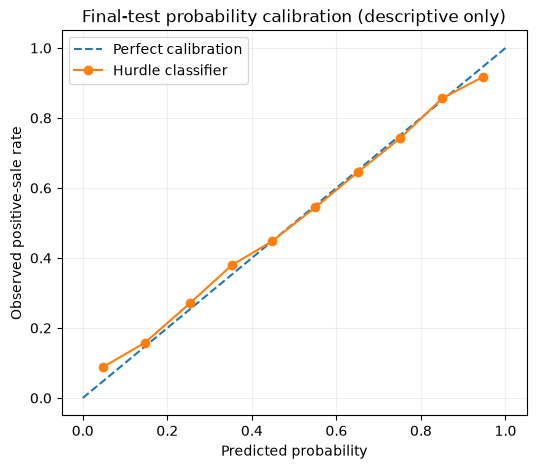

In [27]:
actual_binary=(truth>0).astype(int)
prob=test_result['probability']
quantity=test_result['conditional']
positive=truth>0
brier=float(brier_score_loss(actual_binary.ravel(),prob.ravel()))
positive_mae=float(np.abs(quantity[positive]-truth[positive]).mean()) if positive.any() else np.nan
print('Test Brier score:',round(brier,5))
print('Observed positive-sale rate:',round(float(actual_binary.mean()),5))
print('Mean predicted sale probability:',round(float(prob.mean()),5))
print('Positive-day conditional quantity MAE:',round(positive_mae,4))
calibration=pd.DataFrame({'probability':prob.ravel(),'occurred':actual_binary.ravel()})
calibration['bin']=pd.cut(calibration.probability,bins=np.linspace(0,1,11),include_lowest=True)
calibration_table=calibration.groupby('bin',observed=True).agg(n=('occurred','size'),
    avg_probability=('probability','mean'),observed_rate=('occurred','mean')).reset_index()
display(calibration_table)
plt.figure(figsize=(6,5))
plt.plot([0,1],[0,1],linestyle='--',label='Perfect calibration')
plt.plot(calibration_table.avg_probability,calibration_table.observed_rate,marker='o',label='Hurdle classifier')
plt.xlabel('Predicted probability');plt.ylabel('Observed positive-sale rate')
plt.title('Final-test probability calibration (descriptive only)');plt.legend();plt.grid(alpha=.2);plt.show()


## 8 — Results by demand category and forecast horizon

Report which demand patterns benefit, and whether predictions become worse as the horizon gets longer. Category breakdowns are **descriptive final-test diagnostics**, not permission to tune on the test.

,demand_type,model,series,MAE,MASE,WAPE_pct,bias
1,Erratic,LightGBM_B_calendar,100.0,3.5450,1.0932,70.6419,0.6973
4,Erratic,TSB,100.0,3.5529,1.1232,70.7992,0.3486
0,Erratic,Hurdle_LightGBM,100.0,3.5617,1.0956,70.9760,0.7249
3,Erratic,SES,100.0,3.5623,1.1304,70.9866,0.3325
2,Erratic,SBA,100.0,3.7934,1.2168,75.5927,0.3662
9,Intermittent,TSB,100.0,0.6675,1.9038,110.3969,-0.0224
8,Intermittent,SES,100.0,0.6733,1.9056,111.3518,-0.0213
6,Intermittent,LightGBM_B_calendar,100.0,0.6776,1.9072,112.0582,0.0059
5,Intermittent,Hurdle_LightGBM,100.0,0.6798,1.9214,112.4375,0.0177
7,Intermittent,SBA,100.0,0.8337,1.9237,137.8880,0.1121


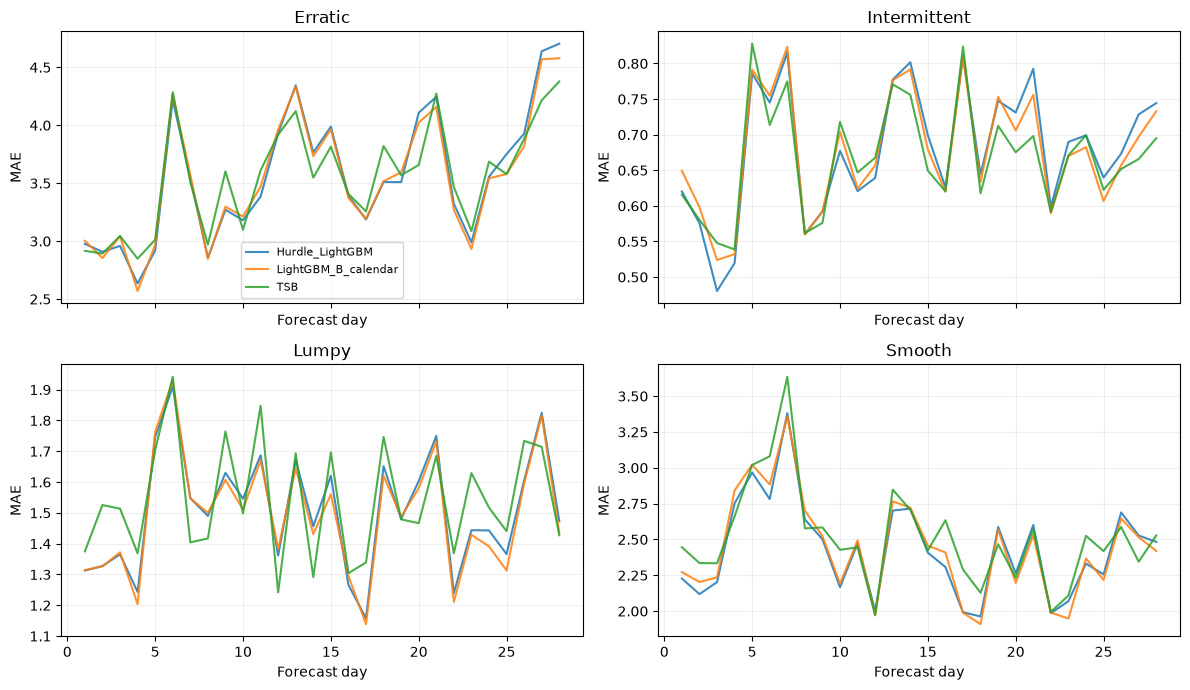

In [28]:
display(by_type[['demand_type','model','series','MAE','MASE','WAPE_pct','bias']].sort_values(['demand_type','MAE']).round(4))
horizon_rows=[]
for name,pred in all_predictions.items():
    for h in range(HORIZON):
        for group in sorted(set(label_types)):
            ix=label_types==group
            horizon_rows.append({'model':name,'demand_type':group,'horizon':h+1,
                                 'MAE':float(np.abs(pred[ix,h]-truth[ix,h]).mean())})
horizon_metrics=pd.DataFrame(horizon_rows)
fig,axs=plt.subplots(2,2,figsize=(12,7),sharex=True)
for ax,category in zip(axs.flat,sorted(set(label_types))):
    for model in ['Hurdle_LightGBM','LightGBM_B_calendar','TSB']:
        view=horizon_metrics.query('demand_type == @category and model == @model')
        ax.plot(view.horizon,view.MAE,label=model,alpha=.85)
    ax.set_title(category);ax.set_ylabel('MAE');ax.set_xlabel('Forecast day');ax.grid(alpha=.2)
axs[0,0].legend(fontsize=8);plt.tight_layout();plt.show()


## 9 — Illustrative forecast trajectories

A direct model can produce a different prediction for each future day. The hurdle forecast is an **expected quantity**, not a discrete sale/no-sale decision.

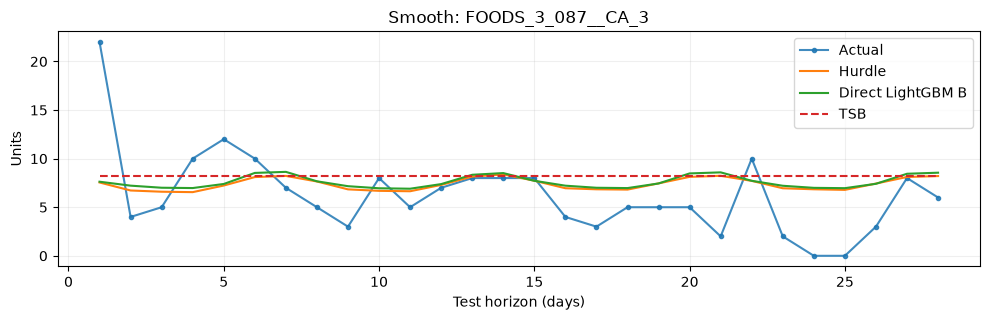

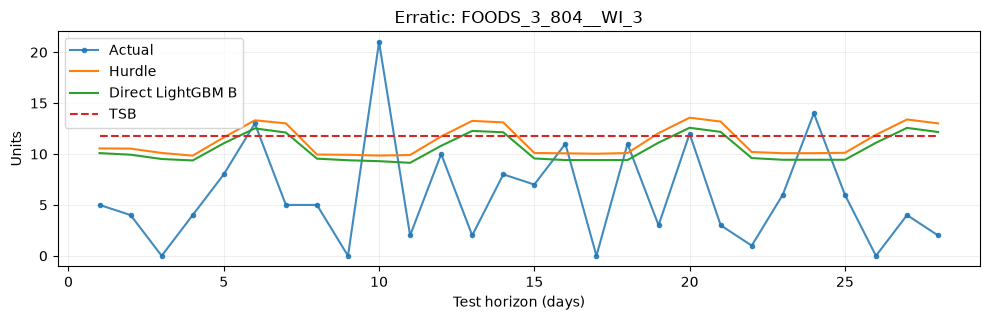

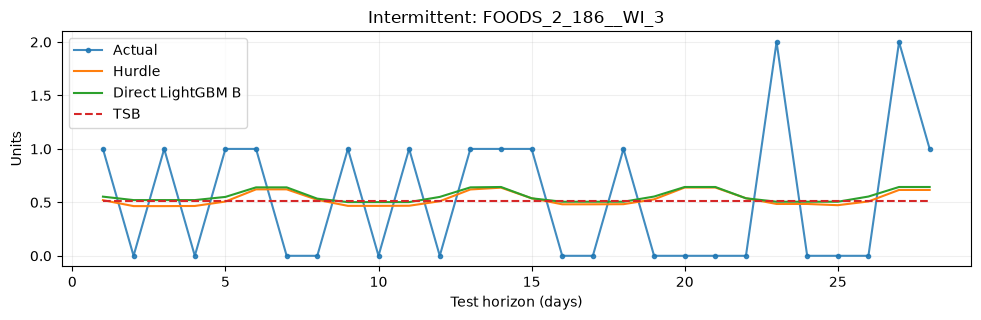

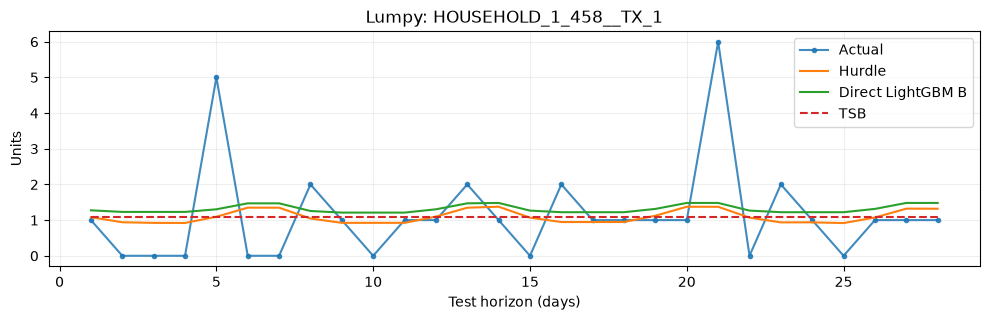

In [29]:
rng=np.random.default_rng(SEED)
for category in ['Smooth','Erratic','Intermittent','Lumpy']:
    candidates=np.flatnonzero(label_types==category)
    if not len(candidates):continue
    i=int(rng.choice(candidates)); x=np.arange(1,HORIZON+1)
    plt.figure(figsize=(10,3.3))
    plt.plot(x,truth[i],marker='.',label='Actual',alpha=.85)
    plt.plot(x,test_result['hurdle'][i],label='Hurdle')
    plt.plot(x,test_result['direct'][i],label='Direct LightGBM B')
    plt.plot(x,baseline_pred['TSB'][i],label='TSB',linestyle='--')
    plt.title(f'{category}: {ids[i]}');plt.xlabel('Test horizon (days)');plt.ylabel('Units')
    plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.show()


## 10 — Save results for reproducibility

All CSVs are written into `data/processed`. For repeated testing, record versions and a run configuration. Do not interpret the final test as a hyperparameter search.

In [ ]:
cv_scores.to_csv(OUT/'phase3b_cv_scores.csv',index=False)
cv_diagnostics.to_csv(OUT/'phase3b_cv_hurdle_diagnostics.csv',index=False)
leaderboard.to_csv(OUT/'phase3b_test_overall.csv',index=False)
by_type.to_csv(OUT/'phase3b_test_by_type.csv',index=False)
metric_rows.to_csv(OUT/'phase3b_test_per_series.csv',index=False)
horizon_metrics.to_csv(OUT/'phase3b_test_by_horizon.csv',index=False)
calibration_table.to_csv(OUT/'phase3b_test_probability_calibration.csv',index=False)
stat_params.to_csv(OUT/'phase3b_statistical_alphas.csv',index=False)
result_rows=[]
for model,pred in all_predictions.items():
    result_rows.append(pd.DataFrame({'series_id':np.repeat(ids,HORIZON),
        'demand_type':np.repeat(label_types,HORIZON),'model':model,
        'horizon':np.tile(np.arange(1,HORIZON+1),S),
        'actual':truth.ravel(),'prediction':pred.ravel()}))
pd.concat(result_rows,ignore_index=True).to_csv(OUT/'phase3b_all_test_forecasts.csv',index=False)
pd.DataFrame({'series_id':np.repeat(ids,HORIZON),'horizon':np.tile(np.arange(1,HORIZON+1),S),
              'prob_positive':prob.ravel(),'expected_units_if_positive':quantity.ravel(),
              'expected_units':test_result['hurdle'].ravel(),'actual':truth.ravel()}).to_csv(
              OUT/'phase3b_hurdle_components.csv',index=False)
print('Saved results to',OUT)
print('LightGBM version:',lgb.__version__,'| pandas:',pd.__version__,'| numpy:',np.__version__)
print('Seed:',SEED,'| horizon:',HORIZON,'| validation origins:',validation_origins,'| test origin:',test_origin)


## 11 — Interpretation and next steps

- **If Hurdle beats direct LightGBM on validation:** investigate whether its advantage persists on the untouched test and in Intermittent/Lumpy categories.
- **If it loses:** that is still valuable. Explicitly separating occurrence and size does not guarantee a better conditional-mean forecast.
- **If the probability is poorly calibrated:** inspect the calibration table and Brier score; probability calibration should be fitted only using training/validation data in a future iteration.
- **If conditional quantity error is high:** the positive-only quantity model may be the bottleneck.
- **After Phase 3B:** consolidate validated forecasters into reusable Python tools, then build LangGraph agents that decide which diagnostic and forecasting tool to invoke. Later improve scientific validation with additional temporal origins, uncertainty intervals, and greater dataset coverage.

**Honest caveat:** Same dataset/test as 3A provides a convenient benchmark but not an independent replication. The final test has already been inspected in Phase 3A; avoid repeated tuning on it.